# FITS on NAB

Reconstruction-based anomaly detection.

- Run all cells. Internet needed for missing NAB files.
- Libraries: PyTorch, NumPy, pandas, Matplotlib, SciPy, scikit-learn.
- Model: [FITS](https://github.com/VEWOXIC/FITS/blob/d040bb015b6299da26d879b90dd19c80fb72c160/AD/FITS.py), adapted under Apache-2.0. Data: [NAB](https://github.com/numenta/NAB).

## Google Colab quick start

1. Upload this notebook to Google Colab. Choose **Runtime > Change runtime type > GPU** when available. The notebook uses CUDA automatically; otherwise it runs on CPU.
2. Before the existing code cells, add and run a setup cell:

   ```python
   %cd /content
   ```

   If a required library is missing, install the packages in another cell before running the notebook. Restart the session if Colab asks:

   ```python
   %pip install torch numpy pandas matplotlib scipy scikit-learn
   ```

3. In the first existing code cell (`1. Setup`), set `RUN_ALL = True` and `SEEDS = [42, 43, 44]` for all 58 series and three seeds. The defaults run only three examples with seed 42.
4. Choose **Runtime > Run all**. Missing NAB data and label files download automatically; no dataset upload or repository clone is required.
5. Results appear below and are saved in `outputs/notebook/all/` or `outputs/notebook/demo/`. See **5. Results** for file names and **7. Save results from Colab** for downloading them.

Colab stores runtime files temporarily. Saving the notebook alone does not save the separate CSV/PNG files to your computer or Google Drive.


## 1. Setup

Default: 3 series, seed 42. All 58 series: `RUN_ALL = True`.


In [1]:
import json
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import maximum_bipartite_matching
from sklearn.metrics import average_precision_score, precision_recall_fscore_support
from IPython.display import display

RUN_ALL = False
SEEDS = [42]  # Optional: [42, 43, 44]
WINDOW, DSR, CUT_FREQ = 200, 4, 25
BATCH_SIZE, EPOCHS, PATIENCE = 128, 50, 5
LEARNING_RATE, QUANTILE = 0.001, 0.99
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT = Path('outputs/notebook') / ('all' if RUN_ALL else 'demo')
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE)

Device: cuda


## 2. NAB Data

Original row order. Train / validation / test: 30% / 20% / 50%.
Standardization from training data only. NAB window labels.

Existing files in `data/raw/NAB/` are reused. Missing CSV files and `labels/combined_windows.json` are downloaded from the fixed NAB version in `NAB_URL`; internet access is required for downloads. With the Colab setup above, the cache is `/content/data/raw/NAB/`.


In [2]:
NAB_ROOT = Path('data/raw/NAB')
NAB_URL = 'https://raw.githubusercontent.com/numenta/NAB/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/'

def nab_file(relative):
    path = NAB_ROOT / relative
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(NAB_URL + relative, path)
    return path

label_windows = json.loads(nab_file('labels/combined_windows.json').read_text(encoding='utf-8'))
series_names = sorted(label_windows) if RUN_ALL else [
    'artificialWithAnomaly/art_daily_jumpsup.csv',
    'realKnownCause/nyc_taxi.csv',
    'artificialNoAnomaly/art_daily_small_noise.csv',
]

def load_series(name):
    frame = pd.read_csv(nab_file('data/' + name))
    times = pd.to_datetime(frame['timestamp'], format='mixed')
    frame['row_id'] = np.arange(len(frame))
    frame['label'] = 0
    for start, end in label_windows[name]:
        frame.loc[times.between(pd.Timestamp(start), pd.Timestamp(end)), 'label'] = 1
    return frame

print('Series:', len(series_names), '| Seeds:', SEEDS)

Series: 3 | Seeds: [42]


## 3. FITS Model

50 input points → normalization → rFFT → complex linear layer → irFFT → 200 reconstructed points.


In [3]:
# Adapted from VEWOXIC/FITS AD/FITS.py, commit d040bb0 (Apache-2.0).
# Univariate interface; explicit inverse-FFT length; return reconstruction only.
class FITS(nn.Module):
    def __init__(self):
        super().__init__()
        self.ratio = WINDOW / (WINDOW // DSR)
        self.freq_upsampler = nn.Linear(CUT_FREQ, int(CUT_FREQ * self.ratio)).to(torch.cfloat)

    def forward(self, x):
        mean = x.mean(dim=1, keepdim=True)
        centered = x - mean
        scale = (centered.var(dim=1, keepdim=True) + 1e-5).sqrt()
        spectrum = torch.fft.rfft(centered / scale, dim=1)[:, :CUT_FREQ]
        expanded = self.freq_upsampler(spectrum.transpose(1, 2)).transpose(1, 2)
        padded = expanded.new_zeros(x.size(0), WINDOW // 2 + 1, 1)
        padded[:, :expanded.size(1)] = expanded
        reconstructed = torch.fft.irfft(padded, n=WINDOW, dim=1) * self.ratio
        return reconstructed * scale + mean

## 4. Training and Scoring

- Adam and MSE. Early stopping after 5 epochs without improvement.
- Stride 1. Mean squared error over overlapping windows.
- Threshold: 99th percentile of validation scores.


In [4]:
def make_loader(values, shuffle=False):
    windows = torch.as_tensor(values, dtype=torch.float32).unfold(0, WINDOW, 1).unsqueeze(-1)
    return DataLoader(windows, batch_size=BATCH_SIZE, shuffle=shuffle)


def epoch_loss(model, loader, optimizer=None):
    model.train(optimizer is not None)
    total = 0.0
    with torch.set_grad_enabled(optimizer is not None):
        for batch in loader:
            target = batch.to(DEVICE)
            if optimizer is not None:
                optimizer.zero_grad()
            loss = (model(target[:, ::DSR]) - target).square().mean()
            if optimizer is not None:
                loss.backward()
                optimizer.step()
            total += loss.item() * len(batch)
    return total / len(loader.dataset)


def train_model(train_values, validation_values, seed):
    torch.manual_seed(seed)
    train_loader = make_loader(train_values, shuffle=True)
    validation_loader = make_loader(validation_values)
    model = FITS().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_loss, waiting, history = float('inf'), 0, []
    for epoch in range(1, EPOCHS + 1):
        train_mse = epoch_loss(model, train_loader, optimizer)
        validation_mse = epoch_loss(model, validation_loader)
        history.append([epoch, train_mse, validation_mse])
        if validation_mse < best_loss:
            best_loss, waiting = validation_mse, 0
            best_weights = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            waiting += 1
        if waiting >= PATIENCE:
            break
    model.load_state_dict(best_weights)
    return model, pd.DataFrame(history, columns=['epoch', 'train_mse', 'validation_mse'])


@torch.no_grad()
def score_series(model, values):
    model.eval()
    score_sum, reconstruction_sum, count = np.zeros((3, len(values)))
    start = 0
    for batch in make_loader(values):
        target = batch.to(DEVICE)
        reconstruction = model(target[:, ::DSR])
        errors = (reconstruction - target).square().squeeze(-1).cpu().numpy()
        indices = np.arange(start, start + len(batch))[:, None] + np.arange(WINDOW)
        np.add.at(score_sum, indices, errors)
        np.add.at(reconstruction_sum, indices, reconstruction.squeeze(-1).cpu().numpy())
        np.add.at(count, indices, 1)
        start += len(batch)
    return score_sum / count, reconstruction_sum / count

## 5. Results

- Raw point metrics; no point adjustment.
- Event F1: maximum one-to-one matching of overlapping events.
- No test anomalies: AP and event F1 left blank; point F1 = 0.
- Macro average: test series with anomalies only.

Training, evaluation, tables and the example plot are generated automatically. With `/content` as the working directory, full-run outputs are in `/content/outputs/notebook/all/`; example-run outputs are in `/content/outputs/notebook/demo/`. Locally, these paths are relative to the working directory. The code prints the actual folder after the run.

| Output | Contents |
| --- | --- |
| `results.csv` | Metrics for each series and seed. |
| `macro_summary.csv` | Per-seed macro averages over test series with positive labels, with the series count. |
| `<category>/<series>/seed_<seed>/predictions.csv` | Test values, labels, reconstructions, anomaly scores, thresholds and predictions. |
| `<category>/<series>/seed_<seed>/history.csv` | Training and validation loss for each epoch. |
| `example.png` | Detection results and loss curves for the first series and seed. |

This notebook currently exports event F1, but not event precision/recall or the mean and standard deviation across seeds. The previously reported full-run tables remain in `outputs/all/`; they are not overwritten by notebook runs.


In [5]:
def events(labels):
    changes = np.diff(np.r_[0, np.asarray(labels, dtype=int), 0])
    return list(zip(np.flatnonzero(changes == 1), np.flatnonzero(changes == -1) - 1))


def evaluate(labels, scores, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='binary', zero_division=0)
    truth, predicted = events(labels), events(predictions)
    matches = 0
    if truth and predicted:
        edges = [[a <= d and c <= b for c, d in predicted] for a, b in truth]
        matching = maximum_bipartite_matching(csr_matrix(np.asarray(edges, dtype=np.int8)), perm_type='column')
        matches = int((matching >= 0).sum())
    false_positives = int(((labels == 0) & (predictions == 1)).sum())
    return dict(ap=average_precision_score(labels, scores) if labels.any() else np.nan,
                point_precision=precision, point_recall=recall, point_f1=f1,
                event_f1=2 * matches / (len(truth) + len(predicted)) if truth else np.nan,
                positive_points=int(labels.sum()), false_positives=false_positives,
                false_positives_per_1000=1000 * false_positives / len(labels))


records, example = [], None
for name in series_names:
    frame = load_series(name)
    values = frame['value'].to_numpy(dtype=np.float64)
    a, b = len(frame) * 30 // 100, len(frame) * 50 // 100
    mean, scale = values[:a].mean(), max(values[:a].std(), 1e-8)
    standardized = ((values - mean) / scale).astype(np.float32)
    train_values, validation_values, test_values = np.split(standardized, [a, b])
    for seed in SEEDS:
        model, history = train_model(train_values, validation_values, seed)
        validation_scores, _ = score_series(model, validation_values)
        threshold = np.quantile(validation_scores, QUANTILE)
        scores, reconstruction = score_series(model, test_values)
        predictions = (scores > threshold).astype(int)
        result = evaluate(frame['label'].to_numpy()[b:], scores, predictions)
        records.append(dict(series_id=name, seed=seed, **result))

        test_frame = frame.iloc[b:].copy()
        test_frame['reconstruction'] = reconstruction * scale + mean
        test_frame['score'], test_frame['prediction'] = scores, predictions
        test_frame['threshold'] = threshold
        folder = OUTPUT / Path(name).with_suffix('') / f'seed_{seed}'
        folder.mkdir(parents=True, exist_ok=True)
        test_frame.to_csv(folder / 'predictions.csv', index=False)
        history.to_csv(folder / 'history.csv', index=False)
        if example is None:
            example = (test_frame, history, threshold, name, seed)
        print(f"{name} | seed={seed} | epochs={len(history)} | AP={result['ap']:.4f} | F1={result['point_f1']:.4f}")

results = pd.DataFrame(records)
results.to_csv(OUTPUT / 'results.csv', index=False)
display(results.round(4))
positive_results = results[results['positive_points'] > 0]
metric_columns = ['ap', 'point_precision', 'point_recall', 'point_f1', 'event_f1']
macro = positive_results.groupby('seed')[metric_columns].mean()
macro['series_count'] = positive_results.groupby('seed').size()
macro.to_csv(OUTPUT / 'macro_summary.csv')
print('Macro average: test series with anomalies')
display(macro.round(4))
print('Saved to:', OUTPUT.resolve())

C:\Users\chen_\miniconda3\envs\eecs6412\lib\site-packages\torch\nn\modules\module.py:1310: UserWarning: Complex modules are a new feature under active development whose design may change, and some modules might not work as expected when using complex tensors as parameters or buffers. Please file an issue at https://github.com/pytorch/pytorch/issues/new?template=bug-report.yml if a complex module does not work as expected.
  warnings.warn(


artificialWithAnomaly/art_daily_jumpsup.csv | seed=42 | epochs=50 | AP=0.7031 | F1=0.6548


C:\Users\chen_\miniconda3\envs\eecs6412\lib\site-packages\torch\nn\modules\module.py:1310: UserWarning: Complex modules are a new feature under active development whose design may change, and some modules might not work as expected when using complex tensors as parameters or buffers. Please file an issue at https://github.com/pytorch/pytorch/issues/new?template=bug-report.yml if a complex module does not work as expected.
  warnings.warn(


realKnownCause/nyc_taxi.csv | seed=42 | epochs=50 | AP=0.2416 | F1=0.0873


C:\Users\chen_\miniconda3\envs\eecs6412\lib\site-packages\torch\nn\modules\module.py:1310: UserWarning: Complex modules are a new feature under active development whose design may change, and some modules might not work as expected when using complex tensors as parameters or buffers. Please file an issue at https://github.com/pytorch/pytorch/issues/new?template=bug-report.yml if a complex module does not work as expected.
  warnings.warn(


artificialNoAnomaly/art_daily_small_noise.csv | seed=42 | epochs=50 | AP=nan | F1=0.0000


,series_id,seed,ap,point_precision,point_recall,point_f1,event_f1,positive_points,false_positives,false_positives_per_1000
0,artificialWithAnomaly/art_daily_jumpsup.csv,42,0.7031,0.9439,0.5012,0.6548,0.0690,403,12,5.9524
1,realKnownCause/nyc_taxi.csv,42,0.2416,0.4545,0.0483,0.0873,0.0909,1035,60,11.6279
2,artificialNoAnomaly/art_daily_small_noise.csv,42,NaN,0.0000,0.0000,0.0000,NaN,0,7,3.4722


Macro average: test series with anomalies


,ap,point_precision,point_recall,point_f1,event_f1,series_count
seed,,,,,,
42,0.4723,0.6992,0.2748,0.3711,0.0799,2


Saved to: D:\Code\EECS6412\Project\outputs\notebook\demo


## 6. Example

First series and seed. Orange: NAB labels. Red: detected anomalies.

Offline reconstruction; future observations may be used. AP/F1 are not official NAB scores.


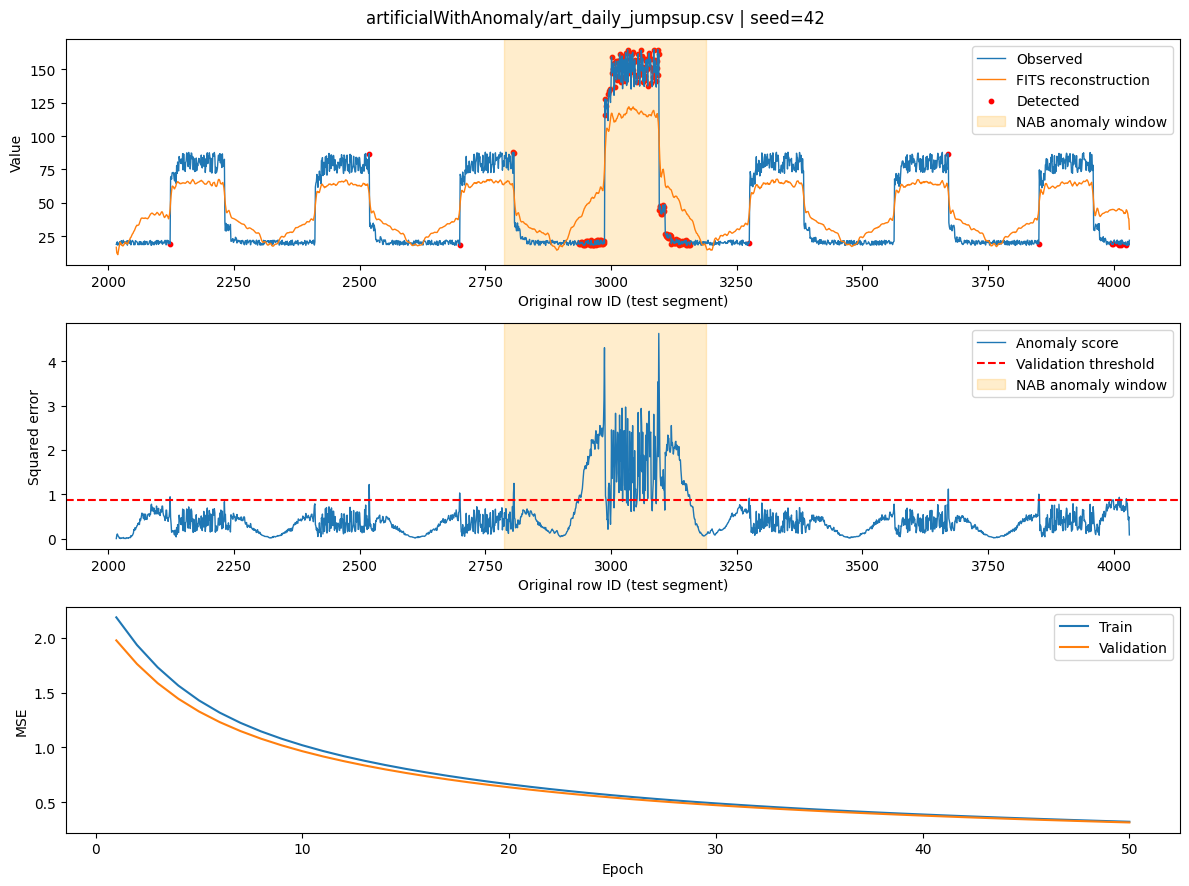

In [6]:
example_frame, history, threshold, name, seed = example
x = example_frame['row_id'].to_numpy()
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

axes[0].plot(x, example_frame['value'], label='Observed', linewidth=1)
axes[0].plot(x, example_frame['reconstruction'], label='FITS reconstruction', linewidth=1)
alarm = example_frame['prediction'].to_numpy().astype(bool)
axes[0].scatter(x[alarm], example_frame['value'].to_numpy()[alarm], color='red', s=10, label='Detected')
axes[0].set_ylabel('Value')
axes[1].plot(x, example_frame['score'], label='Anomaly score', linewidth=1)
axes[1].axhline(threshold, color='red', linestyle='--', label='Validation threshold')
axes[1].set_ylabel('Squared error')
for ax in axes[:2]:
    ax.fill_between(x, 0, 1, where=example_frame['label'].to_numpy().astype(bool),
                    transform=ax.get_xaxis_transform(), color='orange', alpha=0.2, label='NAB anomaly window')
    ax.set_xlabel('Original row ID (test segment)')
    ax.legend(loc='upper right')

axes[2].plot(history['epoch'], history['train_mse'], label='Train')
axes[2].plot(history['epoch'], history['validation_mse'], label='Validation')
axes[2].set(xlabel='Epoch', ylabel='MSE')
axes[2].legend()
fig.suptitle(f'{name} | seed={seed}')
fig.tight_layout()
fig.savefig(OUTPUT / 'example.png', dpi=150)
plt.show()

## 7. Save results from Colab

After the experiment finishes, add a new code cell and run the following to download the notebook output folder as a ZIP:

```python
import shutil
from google.colab import files

archive = shutil.make_archive('/content/fits_nab_results', 'zip',
                              root_dir='/content/outputs/notebook')
files.download(archive)
```

Download the ZIP before the runtime is reset or deleted. Save the executed notebook separately if you also want its displayed outputs. See the [Colab FAQ](https://research.google.com/colaboratory/faq.html) for runtime storage details.
